
# Assignment 2 — Goal-Based Agent: Maze Navigation Using BFS and DFS

### Objective
Implement a goal-based agent that navigates a small maze and finds a path from a start position to a goal position using **BFS** and **DFS**.

### Basic Idea
A goal-based agent selects actions based on whether they help it reach a specified goal.

- **BFS (Breadth-First Search):** explores the maze level by level and finds the shortest path in an unweighted maze.
- **DFS (Depth-First Search):** explores one branch as far as possible before backtracking.


### Step 1 — Import Required Libraries
`deque` is used for the BFS queue.

In [1]:

from collections import deque
import matplotlib.pyplot as plt



### Step 2 — Create the Maze

`0` represents an open cell and `1` represents a wall.

The agent starts at `S` and must reach the goal `G`.


In [2]:

# maze = [
#     [0, 0, 1, 0, 0, 0, 0],
#     [1, 0, 1, 0, 1, 1, 0],
#     [0, 0, 0, 0, 1, 0, 0],
#     [0, 1, 1, 1, 1, 0, 1],
#     [0, 0, 0, 0, 0, 0, 1],
#     [1, 1, 1, 1, 1, 0, 1],
#     [0, 0, 0, 0, 0, 0, 0]
# ]

# start = (0, 0)
# goal = (6, 6)

maze = [
    [0, 1, 1, 0, 0, 0, 0, 0, 1, 1],
    [0, 0, 1, 0, 1, 0, 0, 0, 1, 0],
    [0, 1, 1, 0, 0, 1, 1, 0, 0, 1],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 1, 0, 0, 0, 0, 0, 1],
    [0, 1, 0, 1, 1, 0, 1, 0, 0, 0],
    [1, 0, 1, 0, 0, 1, 0, 0, 0, 1],
    [1, 0, 0, 0, 0, 0, 0, 1, 0, 0]
]

start = (0, 0)
goal = (7, 9)

print("Start:", start)
print("Goal:", goal)


Start: (0, 0)
Goal: (7, 9)


### Step 3 — Display the Maze

In [3]:

def show_maze(path=None):
    path = path or []

    for r in range(len(maze)):
        line = []
        for c in range(len(maze[0])):
            position = (r, c)

            if position == start:
                line.append("S")
            elif position == goal:
                line.append("G")
            elif position in path:
                line.append("*")
            elif maze[r][c] == 1:
                line.append("#")
            else:
                line.append(".")
        print(" ".join(line))


show_maze()


S # # . . . . . # #
. . # . # . . . # .
. # # . . # # . . #
. . . . . . . . . .
. . # # . . . . . #
. # . # # . # . . .
# . # . . # . . . #
# . . . . . . # . G



### Step 4 — Define Valid Moves

The agent can move up, down, left, or right. It cannot move outside the maze or through a wall.


In [4]:

def get_neighbors(position):
    r, c = position

    directions = [
        (-1, 0),  # up
        (1, 0),   # down
        (0, -1),  # left
        (0, 1)    # right
    ]

    neighbors = []

    for dr, dc in directions:
        nr, nc = r + dr, c + dc

        if (0 <= nr < len(maze)
                and 0 <= nc < len(maze[0])
                and maze[nr][nc] == 0):
            neighbors.append((nr, nc))

    return neighbors



### Step 5 — Implement BFS

BFS explores all nearby positions before moving to positions farther away.  
For an unweighted maze, the first path found by BFS is a shortest path.


In [5]:

def bfs(start, goal):
    queue = deque([(start, [start])])
    visited = {start}

    while queue:
        current, path = queue.popleft()

        if current == goal:
            return path

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append((neighbor, path + [neighbor]))

    return None


bfs_path = bfs(start, goal)

print("BFS path:")
print(bfs_path)
print("BFS steps:", len(bfs_path) - 1 if bfs_path else "No path")


BFS path:
[(0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (4, 4), (4, 5), (4, 6), (4, 7), (5, 7), (6, 7), (6, 8), (7, 8), (7, 9)]
BFS steps: 16



### Step 6 — Implement DFS

DFS follows one possible route deeply before backtracking when it reaches a dead end.


In [6]:

def dfs(start, goal):
    stack = [(start, [start])]
    visited = set()

    while stack:
        current, path = stack.pop()

        if current in visited:
            continue

        visited.add(current)

        if current == goal:
            return path

        for neighbor in reversed(get_neighbors(current)):
            if neighbor not in visited:
                stack.append((neighbor, path + [neighbor]))

    return None


dfs_path = dfs(start, goal)

print("DFS path:")
print(dfs_path)
print("DFS steps:", len(dfs_path) - 1 if dfs_path else "No path")


DFS path:
[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (3, 1), (3, 2), (3, 3), (2, 3), (1, 3), (0, 3), (0, 4), (0, 5), (1, 5), (1, 6), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (6, 8), (7, 8), (7, 9)]
DFS steps: 26


### Step 7 — Compare BFS and DFS
This comparison shows whether both algorithms found a path and how many steps each path contains.

In [7]:

print("BFS steps:", len(bfs_path) - 1 if bfs_path else "No path")
print("DFS steps:", len(dfs_path) - 1 if dfs_path else "No path")

if bfs_path and dfs_path:
    if len(bfs_path) < len(dfs_path):
        print("BFS found the shorter path.")
    elif len(dfs_path) < len(bfs_path):
        print("DFS found a shorter path for this maze.")
    else:
        print("Both found paths with the same number of steps.")


BFS steps: 16
DFS steps: 26
BFS found the shorter path.


### Step 8 — Visualize the BFS Path

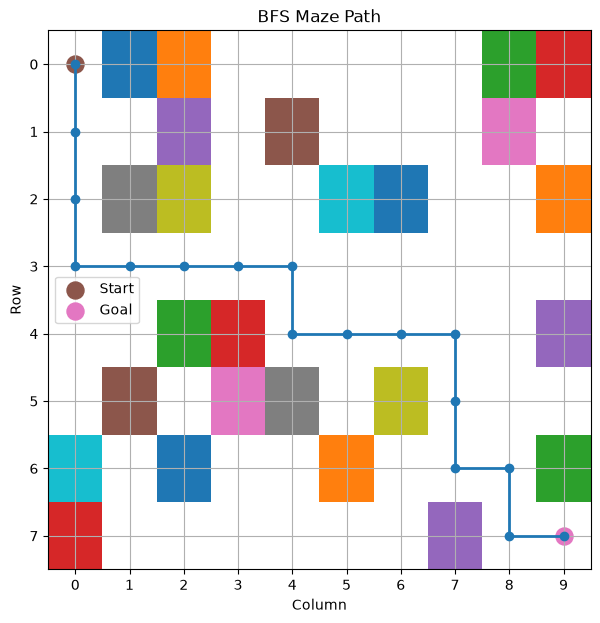

In [8]:

def plot_path(path, title):
    plt.figure(figsize=(7, 7))

    for r in range(len(maze)):
        for c in range(len(maze[0])):
            if maze[r][c] == 1:
                plt.fill_between(
                    [c - 0.5, c + 0.5],
                    [r - 0.5, r - 0.5],
                    [r + 0.5, r + 0.5]
                )

    if path:
        rows = [p[0] for p in path]
        cols = [p[1] for p in path]
        plt.plot(cols, rows, marker="o", linewidth=2)

    plt.scatter(start[1], start[0], s=150, label="Start")
    plt.scatter(goal[1], goal[0], s=150, label="Goal")

    plt.xlim(-0.5, len(maze[0]) - 0.5)
    plt.ylim(len(maze) - 0.5, -0.5)
    plt.xticks(range(len(maze[0])))
    plt.yticks(range(len(maze)))
    plt.grid(True)
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.title(title)
    plt.legend()
    plt.show()


plot_path(bfs_path, "BFS Maze Path")


### Step 9 — Visualize the DFS Path

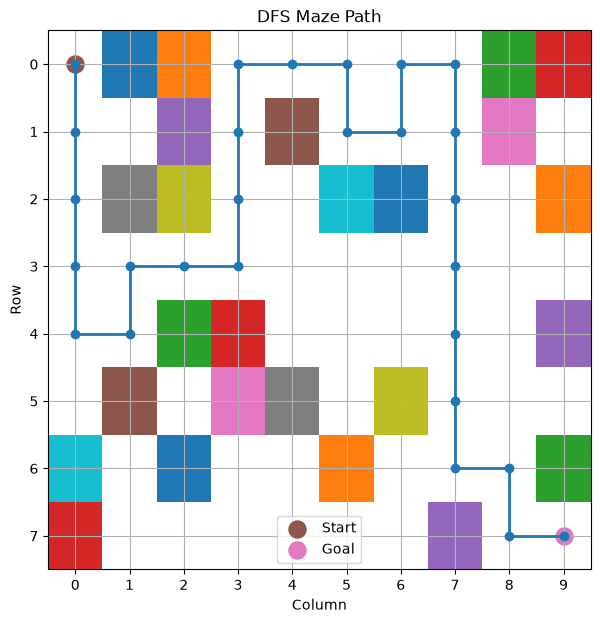

In [9]:
plot_path(dfs_path, "DFS Maze Path")


### Result

Both BFS and DFS successfully search for a route from the start to the goal.

### Conclusion

The assignment demonstrates a **goal-based agent** because the agent's actions are chosen with the objective of reaching a specific goal.

BFS is useful when the shortest path is important. DFS is useful when we want to explore possible routes with a simple depth-first strategy. Depending on the maze structure and neighbor order, BFS and DFS may sometimes produce paths with the same length.
